# Phase 2 : diagnostic de la qualité des données

Ce notebook regroupe les contrôles de la phase 2, avec une section par ticket Jira. Il mesure les problèmes sans rien modifier dans les données : les corrections se font en phase 3.

## Chargement des données

Les quatre tables sont chargées en entier. Les montants et les dates sont convertis en mémoire avec les fonctions de P3-02 et P3-03, pour pouvoir les mesurer. Rien n'est enregistré.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from src.load_data import load_transactions, load_cards, load_users, load_mcc_codes, load_fraud_labels
from src.clean_data import convert_currency_column, convert_month_year_column, US_STATES_AND_TERRITORIES
from src.mcc_families import MCC_TO_FAMILLE
from src.diagnostic import (
    count_missing, check_table_links, check_card_owner, count_inactive,
    explain_missing_location, compare_online_city_channel, count_state_values,
    describe_amounts, round_amounts_by_family, check_user_finances,
    single_value_columns, check_card_info, check_card_dates_vs_transactions,
    age_reference_table, date_card_info, count_error_types,
    find_repeated_transactions, repeated_examples, monthly_counts, check_monthly_continuity,
    check_fraud_labels, add_fraud_label, fraud_summary_by,
)

In [2]:
df_transaction = load_transactions()
df_card = load_cards()
df_users = load_users()
df_mcc = load_mcc_codes()

# Conversions en mémoire seulement (P3-02 et P3-03), pour pouvoir mesurer
df_transaction["amount"] = convert_currency_column(df_transaction["amount"])
df_card["credit_limit"] = convert_currency_column(df_card["credit_limit"])
for col in ["per_capita_income", "yearly_income", "total_debt"]:
    df_users[col] = convert_currency_column(df_users[col])
df_card["expires"] = convert_month_year_column(df_card["expires"], end_of_month=True)
df_card["acct_open_date"] = convert_month_year_column(df_card["acct_open_date"])

for name, df in [("transactions", df_transaction), ("cards", df_card),
                 ("users", df_users), ("mcc", df_mcc)]:
    print(f"{name}: {df.shape[0]:,} lignes, {df.shape[1]} colonnes")

transactions: 13,305,915 lignes, 12 colonnes
cards: 6,146 lignes, 13 colonnes
users: 2,000 lignes, 14 colonnes
mcc: 109 lignes, 2 colonnes


### Valeurs manquantes

Seules les colonnes qui ont au moins une valeur manquante apparaissent.

In [3]:
count_missing({"transactions": df_transaction, "cards": df_card, "users": df_users})

,table,colonne,lignes,manquantes
0,transactions,merchant_state,13305915,1563700
1,transactions,zip,13305915,1652706
2,transactions,errors,13305915,13094522


**Constats**

- Trois colonnes de la table des transactions ont des valeurs manquantes : `merchant_state` (1 563 700), `zip` (1 652 706) et `errors` (13 094 522).
- Les tables `cards` et `users` n'ont aucune valeur manquante.
- Dans `errors`, une valeur manquante veut dire que la transaction n'a pas d'erreur.

## P2-02 : liens entre les tables

Critère de fin : nombre de lignes orphelines pour chaque lien.

In [4]:
check_table_links(df_transaction, df_users, df_card, df_mcc)

,lignes,orphelines
lien,,
transactions.client_id -> users.id,13305915,0
transactions.card_id -> cards.id,13305915,0
cards.client_id -> users.id,6146,0
transactions.mcc -> mcc_codes.mcc_code,13305915,0


**Constats**

- Aucune ligne orpheline pour les quatre liens.
- Chaque transaction a un client, une carte et un code MCC connus. Chaque carte a un client connu.

## P2-03 : la carte utilisée appartient-elle au client ?

Critère de fin : nombre de couples carte et client incohérents.

In [5]:
check_card_owner(df_transaction, df_card)

transactions                                 13305915
transactions avec une carte connue           13305915
client différent du titulaire de la carte           0
dtype: int64

**Constats**

- Les 13 305 915 transactions utilisent une carte connue.
- Le client de la transaction est toujours le titulaire de la carte : 0 cas incohérent.

## P2-04 : clients et cartes sans activité

Critère de fin : chiffres et décision notés.

In [6]:
count_inactive(df_transaction, df_users, df_card)

clients                                      2000
clients sans transaction                      781
cartes                                       6146
cartes sans transaction                      2075
cartes sans transaction d'un client actif     443
dtype: int64

**Constats**

- 781 clients sur 2 000 n'ont aucune transaction.
- 2 075 cartes sur 6 146 n'ont aucune transaction. Parmi elles, 443 appartiennent à un client qui a des transactions avec une autre carte.
- Décision : ces clients et ces cartes restent dans les tables. Les clients sans transaction servent à décrire la population (P5-01), mais pas à construire les profils de comportement (P5-02).

## P2-05 et P2-06 : manquants de merchant_state et de zip

Critères de fin : tableau croisé des manquants et de la ville « ONLINE » ; répartition des manquants par type de lieu.

In [7]:
explain_missing_location(df_transaction, US_STATES_AND_TERRITORIES)

,transactions,merchant_state manquant,zip manquant
type de lieu,,,
en ligne,1563700,1563700,1563700
à l'étranger,89006,0,89006
"États-Unis, sur place",11653209,0,0


**Constats**

- Les 1 563 700 `merchant_state` manquants sont tous des achats en ligne.
- Les 1 652 706 `zip` manquants sont 1 563 700 achats en ligne et 89 006 achats à l'étranger.
- Les achats faits sur place aux États-Unis n'ont aucun manquant. Tous les manquants sont donc expliqués.

## P2-07 : ville « ONLINE » et canal en ligne

Critère de fin : tableau croisé et règle retenue.

In [8]:
compare_online_city_channel(df_transaction)

canal,Chip Transaction,Online Transaction,Swipe Transaction
ville ONLINE,,,
False,4775030,0,6967185
True,5788,1557912,0


**Constats**

- 1 557 912 transactions ont la ville « ONLINE » et le canal « Online Transaction ».
- 5 788 transactions ont la ville « ONLINE » mais le canal « Chip Transaction ».
- Aucune transaction n'a le canal « Online Transaction » avec une autre ville que « ONLINE ».
- Règle retenue (P3-07) : une transaction est en ligne si la ville est « ONLINE » ou si le canal est « Online Transaction ». Les 5 788 cas en désaccord sont gardés et signalés par `online_channel_mismatch`.

## P2-08 : valeurs de merchant_state

Critère de fin : table de correspondance État ou pays.

In [9]:
count_state_values(df_transaction, US_STATES_AND_TERRITORIES)

valeurs distinctes               199
codes d'États américains          52
autres valeurs (pays)            147
codes à deux lettres inconnus      0
dtype: int64

In [10]:
# Valeurs qui ne sont pas des codes d'États américains
states = pd.Series(df_transaction["merchant_state"].dropna().unique()).astype(str)
print(sorted(states[~states.isin(US_STATES_AND_TERRITORIES)]))

# Codes particuliers présents (territoires, DC, forces armées)
print(sorted(set(states) & {"DC", "PR", "GU", "VI", "AS", "MP", "AA"}))

['Albania', 'Algeria', 'Andorra', 'Antigua and Barbuda', 'Argentina', 'Aruba', 'Australia', 'Austria', 'Azerbaijan', 'Bahrain', 'Bangladesh', 'Barbados', 'Belgium', 'Belize', 'Benin', 'Bosnia and Herzegovina', 'Brazil', 'Brunei', 'Burkina Faso', 'Cabo Verde', 'Cameroon', 'Canada', 'Chile', 'China', 'Colombia', 'Costa Rica', "Cote d'Ivoire", 'Croatia', 'Cyprus', 'Czech Republic', 'Denmark', 'Dominican Republic', 'East Timor (Timor-Leste)', 'Ecuador', 'Egypt', 'Equatorial Guinea', 'Eritrea', 'Estonia', 'Ethiopia', 'Fiji', 'Finland', 'France', 'Gabon', 'Georgia', 'Germany', 'Ghana', 'Greece', 'Guatemala', 'Guinea', 'Guyana', 'Haiti', 'Honduras', 'Hong Kong', 'Hungary', 'Iceland', 'India', 'Indonesia', 'Iran', 'Iraq', 'Ireland', 'Israel', 'Italy', 'Jamaica', 'Japan', 'Jordan', 'Kenya', 'Kosovo', 'Kyrgyzstan', 'Latvia', 'Lebanon', 'Liberia', 'Lithuania', 'Luxembourg', 'Macedonia', 'Malaysia', 'Maldives', 'Mali', 'Malta', 'Marshall Islands', 'Mexico', 'Micronesia', 'Moldova', 'Monaco', 'Mong

**Constats**

- `merchant_state` a 199 valeurs distinctes : 52 codes d'États américains et 147 autres valeurs.
- Les 147 autres valeurs sont toutes des noms de pays. Aucun code à deux lettres n'est inconnu.
- Deux codes particuliers sont présents : AA et DC.
- « Georgia » est dans la liste des pays : il s'agit du pays, pas de l'État américain.

## P2-09 : montants des transactions

Critère de fin : tableau des cas et règle de traitement.

In [11]:
describe_amounts(df_transaction["amount"])

transactions         13305915
montants négatifs      660049
montants nuls           10639
minimum                -500.0
quantile 0,1 %         -434.0
médiane                 28.99
quantile 99,9 %        891.54
maximum                6820.2
dtype: object

In [12]:
# Montants entiers (sans centimes) par famille de commerçants
round_amounts_by_family(df_transaction, MCC_TO_FAMILLE)

,transactions,montants_entiers,part_entiers_%
famille,,,
Services professionnels et financiers,718301,578757,80.6
Industrie et fabrication,150735,86207,57.2
Voyage et hébergement,52026,28804,55.4
Alimentation,3182334,606150,19.0
"Transport, carburant et automobile",3352312,632913,18.9
"Maison, jardin et électronique",352851,13479,3.8
Services publics et télécommunications,626682,15230,2.4
Grandes surfaces et commerces divers,1332087,13162,1.0
"Loisirs, culture et divertissement",638844,6303,1.0


**Constats**

- 660 049 montants sont négatifs. Le plus petit est -500,0.
- 10 639 montants sont nuls.
- La médiane vaut 28,99, le quantile 99,9 % vaut 891,54 et le maximum 6 820,2.
- Les montants entiers sont fréquents dans trois familles : services professionnels et financiers (80,6 %), industrie et fabrication (57,2 %), voyage et hébergement (55,4 %).
- Ils représentent 19,0 % en alimentation et 18,9 % en transport. Dans les sept autres familles, ils représentent 3,8 % ou moins.
- Règle (P3-08) : les montants négatifs et nuls sont gardés et signalés par un indicateur. Les montants élevés sont gardés tels quels.

## P2-10 : valeurs financières des clients

Critère de fin : liste des cas et règle de traitement.

In [13]:
check_user_finances(df_users)

clients                                             2000
revenu annuel nul                                      0
revenu annuel inférieur à 1 000                        8
revenu par habitant nul                               15
dette totale nulle                                   102
revenu par habitant supérieur au revenu annuel        34
revenu annuel minimum                                  1
revenu annuel maximum                             307018
score de crédit minimum                              480
score de crédit maximum                              850
dtype: object

In [14]:
# Les revenus annuels les plus bas
df_users.nsmallest(10, "yearly_income")[["id", "yearly_income", "per_capita_income", "total_debt"]]

,id,yearly_income,per_capita_income,total_debt
764,1942,1,0,0
1686,1348,2,0,0
1342,1364,3,0,5
1543,1202,4,0,0
1731,1649,399,0,323
662,1016,553,0,740
1426,1998,645,0,790
751,1151,920,0,1914
1166,1985,1426,0,3154
1100,1530,1785,0,2892


**Constats**

- Aucun client n'a un revenu annuel nul, mais 8 clients ont un revenu annuel inférieur à 1 000. Le plus bas est 1.
- 15 clients ont un revenu par habitant nul. Les 10 revenus annuels les plus bas ont tous un revenu par habitant nul.
- 102 clients ont une dette totale nulle.
- 34 clients ont un revenu par habitant supérieur à leur revenu annuel.
- Le score de crédit va de 480 à 850.
- Règles (P3-08) : un revenu annuel inférieur à 1 000 ou un revenu par habitant nul est signalé par `suspicious_income`. Une dette nulle est possible : elle n'est pas signalée. Les 34 cas de revenu par habitant supérieur au revenu annuel sont gardés.

## P2-11 : informations des cartes

Critère de fin : chiffres et règles de traitement.

In [15]:
print("Colonnes à valeur unique :", single_value_columns(df_card))
check_card_info(df_card)

Colonnes à valeur unique : ['card_on_dark_web']


cartes                                    6146
limite de crédit nulle                      31
expiration avant l'ouverture du compte       0
PIN changé avant l'année d'ouverture         0
PIN changé après l'année d'expiration      268
dtype: int64

In [16]:
# Type des cartes dont la limite de crédit est nulle
df_card.loc[df_card["credit_limit"] == 0, "card_type"].value_counts()

Credit             26
Debit               3
Debit (Prepaid)     2
Name: card_type, dtype: int64

In [17]:
# Transactions faites en dehors de la période de validité de la carte
check_card_dates_vs_transactions(df_transaction, df_card)

,transactions,cartes
cas,,
avant l'ouverture du compte,309,264
après l'expiration de la carte,83,35


**Constats**

- La seule colonne à valeur unique est `card_on_dark_web`.
- 31 cartes ont une limite de crédit nulle : 26 cartes de crédit, 3 cartes de débit et 2 cartes prépayées.
- Aucune carte n'expire avant l'ouverture du compte, et aucun PIN n'a été changé avant l'année d'ouverture.
- 268 cartes ont un changement de PIN après leur année d'expiration.
- 309 transactions, sur 264 cartes, ont eu lieu avant l'ouverture du compte. 83 transactions, sur 35 cartes, ont eu lieu après l'expiration de la carte.
- Règles : `card_on_dark_web` est retirée (P3-09). Les limites nulles sont gardées et signalées par `zero_credit_limit` (P3-08). Les transactions hors de la période de validité sont gardées : elles serviront d'indicateur en phase 4.

## P2-12 : date des informations des clients et des cartes

Critère de fin : conclusion écrite sur la date à laquelle ces informations sont valables.

In [18]:
age_reference_table(df_users)

birth_year + current_age,2019,2020
mois de naissance,,
1,0,192
2,0,197
3,167,0
4,146,0
5,160,0
6,130,0
7,155,0
8,171,0
9,165,0


In [19]:
date_card_info(df_card, df_transaction["date"].max())

dernière transaction                                                         2019-10-31 23:59:00
ouverture de compte la plus récente                                          2020-02-01 00:00:00
cartes ouvertes après la dernière transaction                                               1189
dernière année de changement de PIN                                                         2020
cartes avec un changement de PIN après l'année de la dernière transaction                   1208
dtype: object

**Constats**

- Les clients nés en janvier ou en février ont `birth_year + current_age` = 2020. Ceux nés de mars à décembre ont 2019. L'âge a donc été calculé à la fin de février 2020.
- La dernière transaction date du 31 octobre 2019. L'ouverture de compte la plus récente date du 1er février 2020, et 1 189 cartes ont été ouvertes après la dernière transaction.
- La dernière année de changement de PIN est 2020. 1 208 cartes ont un changement de PIN après 2019.
- Conclusion : les informations des clients et des cartes décrivent la situation de février 2020, après la dernière transaction. L'âge à la date de chaque transaction sera recalculé avec `birth_year` et `birth_month` (P4-03).

## P2-13 : colonne errors

Critère de fin : liste des types d'erreur et de leurs fréquences.

In [20]:
print("Transactions avec au moins une erreur :", df_transaction["errors"].notna().sum())
count_error_types(df_transaction)

Transactions avec au moins une erreur : 211393


Insufficient Balance    131621
Bad PIN                  32482
Technical Glitch         26633
Bad Card Number           7925
Bad Expiration            6295
Bad CVV                   6241
Bad Zipcode               1138
Name: errors, dtype: int64

**Constats**

- 211 393 transactions ont au moins une erreur.
- Il y a sept types d'erreur. Les plus fréquents sont « Insufficient Balance » (131 621), « Bad PIN » (32 482) et « Technical Glitch » (26 633). Le moins fréquent est « Bad Zipcode » (1 138).
- Ces totaux servent de référence au contrôle de P3-06.

## P2-14 : transactions répétées

Même carte, même minute, même montant, même commerçant. Critère de fin : nombre de cas et exemples.

In [21]:
find_repeated_transactions(df_transaction)

lignes dans un groupe répété                      200
groupes répétés                                   100
lignes en plus de la première de chaque groupe    100
groupes avec au moins une erreur                   85
groupes sans aucune erreur                         15
dtype: int64

In [22]:
repeated_examples(df_transaction)

,id,card_id,date,amount,merchant_id,use_chip,errors
3,7842808,2435,2010-04-03 19:59:00,100.0,27092,Swipe Transaction,Bad PIN
2,7842809,2435,2010-04-03 19:59:00,100.0,27092,Swipe Transaction,NaN
0,7659891,3398,2010-02-16 20:27:00,80.0,27092,Swipe Transaction,Insufficient Balance
1,7659892,3398,2010-02-16 20:27:00,80.0,27092,Swipe Transaction,NaN
5,7855862,4734,2010-04-07 06:03:00,180.0,27092,Swipe Transaction,Insufficient Balance
4,7855863,4734,2010-04-07 06:03:00,180.0,27092,Swipe Transaction,NaN


**Constats**

- 100 groupes de transactions répétées, pour 200 lignes : chaque groupe a deux lignes.
- 85 groupes ont au moins une ligne avec une erreur. Dans les trois exemples, la première ligne a une erreur (« Bad PIN » ou « Insufficient Balance ») et la seconde n'en a pas : le client a refait l'achat après un échec.
- 15 groupes n'ont aucune erreur : ce sont de possibles doubles débits.
- Règle (P3-08) : toutes les lignes sont gardées. Dans les 15 groupes sans erreur, la seconde ligne est signalée par `is_repeated`.

## P2-15 : continuité dans le temps

Critère de fin : graphique mensuel commenté.

In [23]:
counts = monthly_counts(df_transaction)
check_monthly_continuity(counts)

premier mois                                 2010-01
dernier mois                                 2019-10
mois attendus                                    118
mois présents                                    118
mois manquants                                     0
mois le plus faible     2010-02 (93470 transactions)
mois le plus fort      2015-12 (119396 transactions)
dtype: object

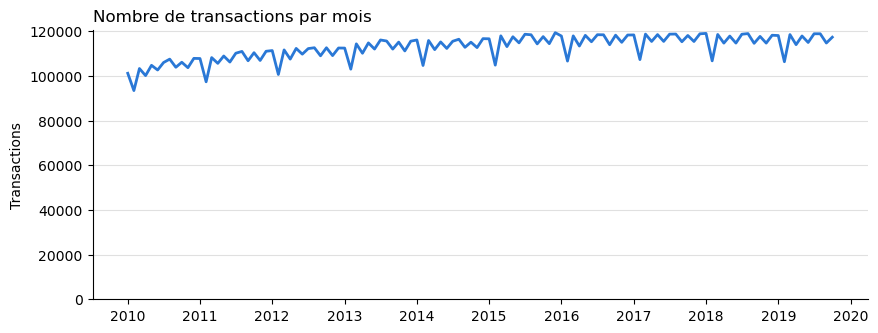

In [24]:
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(
    pd.to_datetime(counts.index.astype(str)),
    counts.to_numpy(dtype=float),
    color="#2a78d6",
    linewidth=2,
)
ax.set_title("Nombre de transactions par mois", loc="left")
ax.set_ylabel("Transactions")
ax.set_ylim(bottom=0)
ax.grid(axis="y", color="#e0e0e0", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**Constats**

- Les 118 mois de janvier 2010 à octobre 2019 sont tous présents : aucun mois ne manque.
- Le mois le plus faible est février 2010 (93 470 transactions). Le plus fort est décembre 2015 (119 396 transactions).
- Le graphique montre une hausse lente jusqu'en 2015, puis un niveau stable. Le nombre baisse chaque mois de février.
- Aucun mois anormal n'est à corriger.

## P2-17 : étiquettes de fraude

La table `fraud_labels.json`, ajoutée par l'enseignant, indique pour une partie des transactions s'il s'agit d'une fraude.

Critère de fin : couverture, taux de fraude et cohérence avec les transactions mesurés et documentés (voir `docs/P2-17_etiquettes_fraude.md`).

In [25]:
df_labels = load_fraud_labels()
print(df_labels.shape)
df_labels.head()

(8914963, 2)


,id,is_fraud
0,10649266,0
1,23410063,0
2,9316588,0
3,12478022,0
4,9558530,0


In [26]:
ok = check_fraud_labels(df_labels, df_transaction)

=== Contrôle P2-17 : étiquettes de fraude ===
  - Transactions étiquetées                 :    8,914,963 (67.0 % des transactions)
  - Identifiants en double                  :            0
  - Identifiants absents des transactions   :            0
  - Fraudes                                 :       13,332 (0.150 % des transactions étiquetées)
Contrôles de cohérence validés : True



### Couverture et taux de fraude par année

In [27]:
# Seules les colonnes utiles sont gardées, pour limiter la mémoire
df_lab = add_fraud_label(df_transaction[["id", "date", "use_chip"]], df_labels)
df_lab["annee"] = df_lab["date"].dt.year
fraud_summary_by(df_lab, "annee")

,n_transactions,n_etiquetees,n_fraudes,part_etiquetee_%,taux_fraude_%
annee,,,,,
2010,1240880,831529,2573,67.0,0.309
2011,1290770,863428,37,66.9,0.004
2012,1321672,885421,923,67.0,0.104
2013,1352808,907304,1337,67.1,0.147
2014,1365537,915073,664,67.0,0.073
2015,1388065,930224,2189,67.0,0.235
2016,1392117,932762,2448,67.0,0.262
2017,1399308,937284,172,67.0,0.018
2018,1394792,934599,1629,67.0,0.174


### Couverture et taux de fraude par canal de paiement

In [28]:
fraud_summary_by(df_lab, "use_chip")

,n_transactions,n_etiquetees,n_fraudes,part_etiquetee_%,taux_fraude_%
use_chip,,,,,
Swipe Transaction,6967185,4668212,1377,67.0,0.029
Online Transaction,1557912,1043975,8779,67.0,0.841
Chip Transaction,4780818,3202776,3176,67.0,0.099


**Constats**

- 8 914 963 transactions sont étiquetées, soit 67,0 % du total. Aucun identifiant n'est en double, et tous existent dans les transactions.
- 13 332 sont des fraudes, soit 0,150 % des transactions étiquetées : les deux classes sont très déséquilibrées.
- La part étiquetée est comprise entre 66,9 % et 67,1 % selon l'année, et vaut 67,0 % pour chaque canal. Les étiquettes semblent donc tirées au hasard : la partie étiquetée représente bien l'ensemble.
- Le taux de fraude varie beaucoup selon l'année : de 0,004 % en 2011 (37 fraudes) à 0,309 % en 2010. Il faudra en tenir compte pour séparer les données d'entraînement et de test (P7-08).
- Le taux de fraude est de 0,841 % en ligne, 0,099 % par puce et 0,029 % par bande magnétique. Le canal de paiement sera un indicateur à suivre en phase 4.

## P2-16 : rapport de diagnostic

Le rapport reprend les résultats de ce notebook, problème par problème, avec la règle retenue pour la phase 3 : `docs/P2-16_rapport_diagnostic.md`.